# 03. Telco Churn - классификация

Бинарная классификация: предсказать `Churn` (No - клиент остался, Yes - ушёл).

**Датасет:** 7 043 × 21. **Дисбаланс классов:** 73.5 / 26.5.

**Протокол - тот же, что для credit (02):**

1. Проверка качества данных.
2. Препроцессинг: `customerID`, `TotalCharges`, таргет.
3. Train / test split 80/20 со стратификацией, тест откладывается.
4. Кросс-валидация `StratifiedKFold(5)` на train: 9 моделей + CatBoost с нативными категориями, ROC-AUC + F1.
5. Подбор гиперпараметров `RandomizedSearchCV` на train.
6. Финальная оценка на тесте.

In [1]:
import sys
from pathlib import Path

KAGGLE_CONFIG_PATHS = [
    Path("/kaggle/input/project-config"),
    Path("/kaggle/input/kirylloffix/project-config"),
]

for p in KAGGLE_CONFIG_PATHS:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
        break

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from config import Config


warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

config = Config()
RANDOM_STATE = config.RANDOM_STATE
np.random.seed(RANDOM_STATE)
print(config)

Config(mode='local', credit='/home/claude/proj/data/credit_risk_dataset.csv', churn='/home/claude/proj/data/WA_Fn-UseC_-Telco-Customer-Churn.csv', demand='/home/claude/proj/data/train.csv', random_state=42)


In [2]:
DATASET = 'churn'
PLOT_PATH = config.churn_plot

df_churn = pd.read_csv(config.path_churn)
print("churn:", df_churn.shape)
df_churn.head()

churn: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Проверка качества данных

- `customerID` - идентификатор, не признак.
- `TotalCharges` хранится строкой: в 11 строках там пробел.
- Проверяем, насколько точно `TotalCharges ≈ tenure × MonthlyCharges` - на этом построено заполнение.

In [3]:
tc = pd.to_numeric(df_churn['TotalCharges'], errors='coerce')
blank = tc.isna()

print(f"customerID уникальных: {df_churn['customerID'].nunique()} из {len(df_churn)}")
print(f"TotalCharges не число: {blank.sum()} строк")
print(f"tenure у этих строк: {df_churn.loc[blank, 'tenure'].unique().tolist()}")

ratio = tc / (df_churn['tenure'] * df_churn['MonthlyCharges'])
print(f"\nTotalCharges / (tenure * MonthlyCharges): медиана {ratio.median():.3f}, "
      f"50% значений в [{ratio.quantile(0.25):.3f}; {ratio.quantile(0.75):.3f}]")
print(f"Совпадающих строк без customerID: {df_churn.drop(columns='customerID').duplicated().sum()} "
      f"(это разные клиенты с одинаковыми параметрами - не удаляем)")

customerID уникальных: 7043 из 7043
TotalCharges не число: 11 строк
tenure у этих строк: [0]

TotalCharges / (tenure * MonthlyCharges): медиана 1.000, 50% значений в [0.980; 1.020]
Совпадающих строк без customerID: 22 (это разные клиенты с одинаковыми параметрами - не удаляем)


## Препроцессинг

**`customerID`** - удаляем.

**`TotalCharges`** -> `pd.to_numeric(errors='coerce')`, пустые строки становятся `NaN` (11 значений).

**Заполнение - по формуле, а не медианой.** `TotalCharges ≈ tenure × MonthlyCharges` (медиана отношения = 1.000).
У всех 11 пустых строк `tenure = 0` - это новые клиенты, которым ещё ничего не начислили, поэтому формула даёт **0**,
и это правильное значение. Глобальная медиана (~1 400) приписала бы новому клиенту полтора года платежей.

Формула - фиксированное правило, а не статистика, выученная по данным, поэтому применять её до разбиения можно (утечки нет).

**Таргет** - `Churn` -> `map({'No': 0, 'Yes': 1})`.

In [4]:
churn = df_churn.copy()

churn = churn.drop(columns=['customerID'])

churn['TotalCharges'] = pd.to_numeric(churn['TotalCharges'], errors='coerce')

mask = churn['TotalCharges'].isna()
churn.loc[mask, 'TotalCharges'] = churn.loc[mask, 'tenure'] * churn.loc[mask, 'MonthlyCharges']
print("подставленные значения TotalCharges:", churn.loc[mask, 'TotalCharges'].unique().tolist())

churn['Churn'] = churn['Churn'].map({'No': 0, 'Yes': 1})

X_churn = churn.drop(columns=['Churn'])
y_churn = churn['Churn']

num_cols = X_churn.select_dtypes(include='number').columns.tolist()
cat_cols = X_churn.select_dtypes(exclude='number').columns.tolist()

print(f"shape: {churn.shape}")
print(f"пропуски: {churn.isna().sum().sum()}")
print(f"доля класса 1: {y_churn.mean():.4f}")
print(f"числовые ({len(num_cols)}): {num_cols}")
print(f"категориальные ({len(cat_cols)}): {cat_cols}")

подставленные значения TotalCharges: [0.0]
shape: (7043, 20)
пропуски: 0
доля класса 1: 0.2654
числовые (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
категориальные (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Train / test split

Как в credit: 80/20, `stratify=y`, `random_state=42`. Тест откладываем до конца.

In [5]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X_churn, y_churn,
    test_size=0.2,
    stratify=y_churn,
    random_state=RANDOM_STATE
)

print(f"train: {X_train.shape}, test: {X_test.shape}")
print(f"доля класса 1 в train: {y_train.mean():.4f}")
print(f"доля класса 1 в test:  {y_test.mean():.4f}")

train: (5634, 19), test: (1409, 19)
доля класса 1 в train: 0.2654
доля класса 1 в test:  0.2654


## Препроцессор и пайплайн

**Ошибка прошлой версии:** `preprocessor_churn` использовался, но нигде не был определён - ноутбук падал с `NameError`.

`ColumnTransformer` - тот же по логике, что и в credit:

- `StandardScaler` к 4 числовым;
- `OneHotEncoder` к 15 категориальным (2-4 значения в каждой).

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression


def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ])


def make_pipeline_for(model):
    if model.get_params().get('cat_features') is not None:
        return Pipeline([('model', model)])  # CatBoost-native кодирует категории сам
    return Pipeline([('prep', make_preprocessor()), ('model', model)])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipe_logreg = make_pipeline_for(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
scores = cross_val_score(pipe_logreg, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

print(f"Baseline LogReg, ROC-AUC по фолдам: {scores.round(4)}")
print(f"Среднее: {scores.mean():.4f} ± {scores.std():.4f}")

Baseline LogReg, ROC-AUC по фолдам: [0.8479 0.8252 0.8419 0.863  0.853 ]
Среднее: 0.8462 ± 0.0126


## Кросс-валидация 9 моделей на train

Прогоняем 9 моделей **на одном и том же** пайплайне и одних и тех же фолдах:

- **Линейные:** LogReg
- **Деревья:** DecisionTree
- **Бэггинг:** RandomForest
- **Бустинг:** XGBoost, LightGBM, CatBoost
- **Метрические:** kNN
- **Разделяющая полоса (margin):** SVM (rbf)
- **Вероятностные:** NaiveBayes

Здесь гиперпараметры **фиксированные** (одинаковые «разумные значения по умолчанию» для всех датасетов).
Это первая стадия протокола: честное сравнение семейств без подгонки.

Что важно в коде:

- CV идёт **только по `X_train`**: тест не участвует ни в обучении, ни в выборе модели;
- `cross_validate` считает сразу две метрики - **ROC-AUC** и **F1** (порог 0.5);
- `return_train_score=True` - ROC-AUC на обучающих фолдах. Разница train - val показывает **переобучение**;
- `CatBoost(allow_writing_files=False)` - иначе параллельные процессы конфликтуют из-за папки `catboost_info`
  и часть фолдов падает (так было в прошлой версии 02_credit: CatBoost = `NaN`);
- у `SVC` не включаем `probability=True`: для ROC-AUC достаточно `decision_function`
  (ранжирование то же самое), а обучение в ~5 раз быстрее;
- у самих моделей `n_jobs=1` (`thread_count=1` у CatBoost): параллелим фолды (`n_jobs=-1` в `cross_validate`), а не потоки внутри модели. Иначе на 2 ядрах 2 процесса × все ядра конкурируют, и бустинги замедляются в разы. На результат это не влияет;
- метрики **по каждому фолду** сохраняются в CSV - на них потом строится тест Фридмана в `05_statistics`.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB


models = {
    'LogReg':       LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'DecisionTree': DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    'RandomForest': RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=RANDOM_STATE),
    'XGBoost':      XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                  eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=1),
    'LightGBM':     LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                   random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
    'CatBoost':     CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,
                                       random_state=RANDOM_STATE, verbose=0,
                                       allow_writing_files=False, thread_count=1),
    'kNN':          KNeighborsClassifier(n_neighbors=15, n_jobs=1),
    'SVM':          SVC(kernel='rbf', C=1.0, random_state=RANDOM_STATE),
    'NaiveBayes':   GaussianNB(),
}

### CatBoost с нативными категориальными признаками

Десятая модель - тот же CatBoost, но **без OneHot**: подаём категории строками и указываем `cat_features`.
CatBoost кодирует их сам через **ordered target statistics** (среднее таргета по категории, посчитанное
только по «предыдущим» объектам - без утечки таргета).

**Исправление прошлой версии.** Там было написано, что `cross_val_score` конвертирует DataFrame в numpy и
CatBoost теряет имена колонок, поэтому был написан ручной цикл. Это не так: sklearn передаёт в модель
DataFrame как есть, поэтому CatBoost-native идёт через тот же `cross_validate`, на тех же фолдах.
Для этого `make_pipeline_for` не добавляет OneHot, если у модели заданы `cat_features`.

В тест Фридмана (`05_statistics`) CatBoost-native не входит: он есть только на churn, а Фридману нужен
одинаковый набор моделей на всех датасетах.

In [8]:
cat_feature_names = X_churn.select_dtypes(exclude='number').columns.tolist()

models['CatBoost_native'] = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1,
    cat_features=tuple(cat_feature_names),  # tuple, а не list: иначе sklearn.clone падает
    random_state=RANDOM_STATE, verbose=0, allow_writing_files=False, thread_count=1,
)
print("cat_features:", cat_feature_names)
print("моделей:", len(models))

cat_features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
моделей: 10


In [9]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate


fold_rows = []
results = {}

for name, model in models.items():
    pipe = make_pipeline_for(clone(model))
    cvres = cross_validate(
        pipe, X_train, y_train,
        cv=cv,
        scoring={'roc_auc': 'roc_auc', 'f1': 'f1'},
        return_train_score=True,
        n_jobs=-1,
        error_score='raise',
    )
    for i in range(cv.get_n_splits()):
        fold_rows.append({
            'dataset': DATASET, 'model': name, 'fold': i,
            'roc_auc': cvres['test_roc_auc'][i],
            'f1': cvres['test_f1'][i],
            'train_roc_auc': cvres['train_roc_auc'][i],
        })
    results[name] = {
        'roc_auc_mean':  cvres['test_roc_auc'].mean(),
        'roc_auc_std':   cvres['test_roc_auc'].std(),
        'f1_mean':       cvres['test_f1'].mean(),
        'f1_std':        cvres['test_f1'].std(),
        'train_roc_auc': cvres['train_roc_auc'].mean(),
    }
    print(f"{name:15} ROC-AUC: {cvres['test_roc_auc'].mean():.4f} ± {cvres['test_roc_auc'].std():.4f}   "
          f"F1: {cvres['test_f1'].mean():.4f} ± {cvres['test_f1'].std():.4f}   "
          f"train ROC-AUC: {cvres['train_roc_auc'].mean():.4f}")

LogReg          ROC-AUC: 0.8462 ± 0.0126   F1: 0.5923 ± 0.0299   train ROC-AUC: 0.8496


DecisionTree    ROC-AUC: 0.7482 ± 0.0126   F1: 0.5293 ± 0.0151   train ROC-AUC: 0.9554


RandomForest    ROC-AUC: 0.8199 ± 0.0126   F1: 0.5374 ± 0.0278   train ROC-AUC: 0.9999


XGBoost         ROC-AUC: 0.8347 ± 0.0082   F1: 0.5705 ± 0.0219   train ROC-AUC: 0.9757


LightGBM        ROC-AUC: 0.8331 ± 0.0080   F1: 0.5652 ± 0.0282   train ROC-AUC: 0.9746


CatBoost        ROC-AUC: 0.8397 ± 0.0101   F1: 0.5692 ± 0.0201   train ROC-AUC: 0.9481


kNN             ROC-AUC: 0.8224 ± 0.0084   F1: 0.5780 ± 0.0158   train ROC-AUC: 0.8652


SVM             ROC-AUC: 0.7998 ± 0.0158   F1: 0.5735 ± 0.0162   train ROC-AUC: 0.8655


NaiveBayes      ROC-AUC: 0.8212 ± 0.0119   F1: 0.5974 ± 0.0093   train ROC-AUC: 0.8218


CatBoost_native ROC-AUC: 0.8434 ± 0.0103   F1: 0.5799 ± 0.0195   train ROC-AUC: 0.8987


## Таблица результатов CV

Сортировка по среднему ROC-AUC, убывание.

`overfit_gap` = ROC-AUC на train-фолдах − ROC-AUC на валидации. Чем больше, тем сильнее модель «зазубрила» обучающие данные.

In [10]:
results_df = pd.DataFrame(results).T.sort_values('roc_auc_mean', ascending=False)
results_df['overfit_gap'] = results_df['train_roc_auc'] - results_df['roc_auc_mean']
print(results_df.round(4))

folds_df = pd.DataFrame(fold_rows)
folds_df.to_csv(config.cv_folds(DATASET), index=False)
print(f"\nМетрики по фолдам сохранены: {config.cv_folds(DATASET)}")
print("Моделей:", folds_df['model'].nunique(), "| фолдов:", folds_df['fold'].nunique())

                 roc_auc_mean  roc_auc_std  f1_mean  f1_std  train_roc_auc  \
LogReg                 0.8462       0.0126   0.5923  0.0299         0.8496   
CatBoost_native        0.8434       0.0103   0.5799  0.0195         0.8987   
CatBoost               0.8397       0.0101   0.5692  0.0201         0.9481   
XGBoost                0.8347       0.0082   0.5705  0.0219         0.9757   
LightGBM               0.8331       0.0080   0.5652  0.0282         0.9746   
kNN                    0.8224       0.0084   0.5780  0.0158         0.8652   
NaiveBayes             0.8212       0.0119   0.5974  0.0093         0.8218   
RandomForest           0.8199       0.0126   0.5374  0.0278         0.9999   
SVM                    0.7998       0.0158   0.5735  0.0162         0.8655   
DecisionTree           0.7482       0.0126   0.5293  0.0151         0.9554   

                 overfit_gap  
LogReg                0.0034  
CatBoost_native       0.0554  
CatBoost              0.1085  
XGBoost          

## Bar plot

Топ-3 - зелёным, остальные - синим. Усы - стандартное отклонение по 5 фолдам.

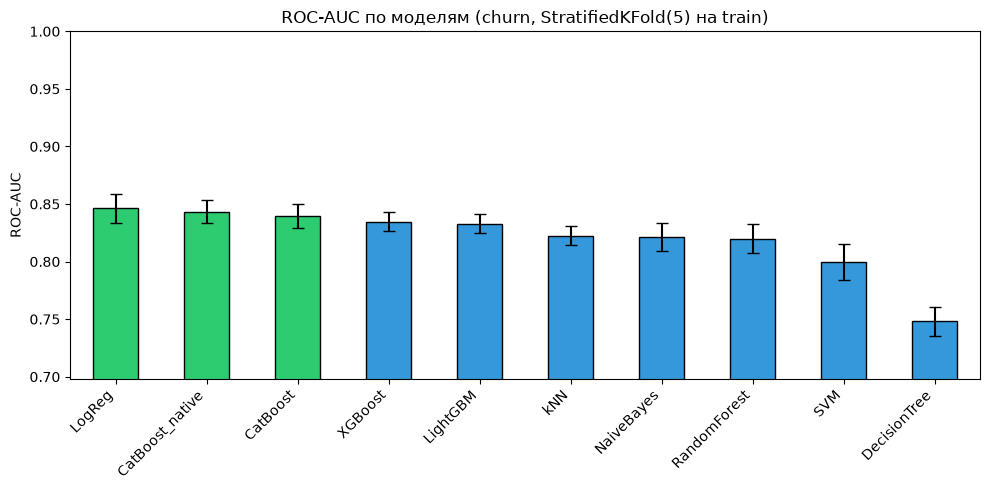

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#2ecc71' if i < 3 else '#3498db' for i in range(len(results_df))]

results_df['roc_auc_mean'].plot(
    kind='bar', yerr=results_df['roc_auc_std'], ax=ax,
    color=colors, capsize=4, edgecolor='black'
)
ax.set_ylim(results_df['roc_auc_mean'].min() - 0.05, 1.0)
ax.set_title(f'ROC-AUC по моделям ({DATASET}, StratifiedKFold(5) на train)')
ax.set_ylabel('ROC-AUC')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(PLOT_PATH, dpi=150)
plt.show()

## Подбор гиперпараметров (RandomizedSearchCV)

Вторая стадия протокола. Для **каждой** модели:

1. `RandomizedSearchCV` перебирает `n_iter` случайных комбинаций гиперпараметров;
2. каждая комбинация оценивается внутренней кросс-валидацией `StratifiedKFold(3)` **только на train**;
3. лучшая комбинация переобучается на всём train (`refit=True`);
4. итоговая модель **один раз** оценивается на отложенном тесте.

`n_iter = 20` для большинства моделей, 15 - для моделей с 1 гиперпараметром, 8 - для SVM (она самая медленная).
Это компромисс между качеством подбора и временем на 2 ядрах.

**Почему тест честный:** тест не участвовал ни в выборе гиперпараметров, ни в выборе модели.

`cv_roc_auc_tuned` - лучший результат внутри поиска. Он **оптимистичен** (мы выбрали максимум из многих попыток),
поэтому сравниваем модели по `test_roc_auc`.

In [12]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform


param_spaces = {
    'LogReg': {
        'model__C': loguniform(1e-3, 1e2),
    },
    'DecisionTree': {
        'model__max_depth': [3, 4, 5, 6, 8, 10, 12, 15, None],
        'model__min_samples_leaf': randint(1, 100),
    },
    'RandomForest': {
        'model__n_estimators': [200, 300, 400],
        'model__max_depth': [None, 10, 15, 20, 30],
        'model__min_samples_leaf': [1, 2, 4, 8],
        'model__max_features': ['sqrt', 0.3, 0.5],
    },
    'XGBoost': {
        'model__n_estimators': randint(200, 700),
        'model__max_depth': randint(3, 10),
        'model__learning_rate': loguniform(0.01, 0.3),
        'model__subsample': uniform(0.6, 0.4),
        'model__colsample_bytree': uniform(0.6, 0.4),
        'model__min_child_weight': randint(1, 10),
    },
    'LightGBM': {
        'model__n_estimators': randint(200, 700),
        'model__num_leaves': randint(15, 128),
        'model__max_depth': [-1, 6, 8, 10],
        'model__learning_rate': loguniform(0.01, 0.3),
        'model__subsample': uniform(0.6, 0.4),
        'model__subsample_freq': [1],
        'model__colsample_bytree': uniform(0.6, 0.4),
        'model__min_child_samples': randint(5, 100),
    },
    'CatBoost': {
        'model__iterations': randint(200, 600),
        'model__depth': randint(4, 9),
        'model__learning_rate': loguniform(0.01, 0.3),
        'model__l2_leaf_reg': loguniform(1, 10),
    },
    'kNN': {
        'model__n_neighbors': randint(5, 150),
        'model__weights': ['uniform', 'distance'],
    },
    'SVM': {
        'model__C': loguniform(0.1, 100),
        'model__gamma': ['scale', 0.01, 0.03, 0.1, 0.3],
    },
    'NaiveBayes': {
        'model__var_smoothing': loguniform(1e-12, 1e-2),
    },
}

N_ITER = {name: 20 for name in models}
N_ITER.update({'LogReg': 15, 'NaiveBayes': 15, 'SVM': 8})

inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

In [13]:
param_spaces['CatBoost_native'] = param_spaces['CatBoost']
N_ITER['CatBoost_native'] = N_ITER['CatBoost']

In [14]:
import time
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score


def ranking_scores(estimator, X):
    """Оценки для ROC-AUC: вероятность класса 1 или decision_function (у SVC без probability)."""
    if hasattr(estimator, 'predict_proba'):
        return estimator.predict_proba(X)[:, 1]
    return estimator.decision_function(X)


test_rows = []

for name, model in models.items():
    t0 = time.time()
    search = RandomizedSearchCV(
        make_pipeline_for(clone(model)),
        param_distributions=param_spaces[name],
        n_iter=N_ITER[name],
        cv=inner_cv,
        scoring='roc_auc',
        n_jobs=-1,
        random_state=RANDOM_STATE,
        refit=True,
    )
    search.fit(X_train, y_train)
    best = search.best_estimator_

    y_score = ranking_scores(best, X_test)
    y_pred = best.predict(X_test)

    test_rows.append({
        'dataset': DATASET,
        'model': name,
        'cv_roc_auc_default': results[name]['roc_auc_mean'],
        'cv_roc_auc_tuned': search.best_score_,
        'test_roc_auc': roc_auc_score(y_test, y_score),
        'test_f1': f1_score(y_test, y_pred),
        'test_precision': precision_score(y_test, y_pred),
        'test_recall': recall_score(y_test, y_pred),
        'best_params': {k.replace('model__', ''): (round(float(v), 5) if isinstance(v, (float, np.floating)) else v)
                        for k, v in search.best_params_.items()},
    })
    print(f"{name:15} CV(default) {results[name]['roc_auc_mean']:.4f} -> CV(tuned) {search.best_score_:.4f} | "
          f"TEST ROC-AUC {test_rows[-1]['test_roc_auc']:.4f}  F1 {test_rows[-1]['test_f1']:.4f}  "
          f"({time.time() - t0:.0f} c)")

LogReg          CV(default) 0.8462 -> CV(tuned) 0.8461 | TEST ROC-AUC 0.8409  F1 0.5945  (2 c)


DecisionTree    CV(default) 0.7482 -> CV(tuned) 0.8374 | TEST ROC-AUC 0.8317  F1 0.5495  (2 c)


RandomForest    CV(default) 0.8199 -> CV(tuned) 0.8468 | TEST ROC-AUC 0.8423  F1 0.5740  (49 c)


XGBoost         CV(default) 0.8347 -> CV(tuned) 0.8489 | TEST ROC-AUC 0.8482  F1 0.5745  (15 c)


LightGBM        CV(default) 0.8331 -> CV(tuned) 0.8496 | TEST ROC-AUC 0.8493  F1 0.5655  (19 c)


CatBoost        CV(default) 0.8397 -> CV(tuned) 0.8486 | TEST ROC-AUC 0.8455  F1 0.5736  (57 c)


kNN             CV(default) 0.8224 -> CV(tuned) 0.8341 | TEST ROC-AUC 0.8317  F1 0.5884  (5 c)


SVM             CV(default) 0.7998 -> CV(tuned) 0.8368 | TEST ROC-AUC 0.8320  F1 0.5552  (12 c)


NaiveBayes      CV(default) 0.8212 -> CV(tuned) 0.8210 | TEST ROC-AUC 0.8077  F1 0.5928  (1 c)


CatBoost_native CV(default) 0.8434 -> CV(tuned) 0.8497 | TEST ROC-AUC 0.8459  F1 0.5898  (178 c)


## Итог на отложенном тесте

`test_f1`, `test_precision`, `test_recall` - при пороге 0.5. Порог не подбирался.

In [15]:
test_df = pd.DataFrame(test_rows).set_index('model').sort_values('test_roc_auc', ascending=False)
test_df.to_csv(config.test_results(DATASET))

pd.set_option('display.width', 200)
print(test_df.drop(columns=['dataset', 'best_params']).round(4))
print()
for name, row in test_df.iterrows():
    print(f"{name:15} {row['best_params']}")
print(f"\nСохранено: {config.test_results(DATASET)}")

                 cv_roc_auc_default  cv_roc_auc_tuned  test_roc_auc  test_f1  test_precision  test_recall
model                                                                                                    
LightGBM                     0.8331            0.8496        0.8493   0.5655          0.7024       0.4733
XGBoost                      0.8347            0.8489        0.8482   0.5745          0.6751       0.5000
CatBoost_native              0.8434            0.8497        0.8459   0.5898          0.6701       0.5267
CatBoost                     0.8397            0.8486        0.8455   0.5736          0.6827       0.4947
RandomForest                 0.8199            0.8468        0.8423   0.5740          0.6690       0.5027
LogReg                       0.8462            0.8461        0.8409   0.5945          0.6458       0.5508
SVM                          0.7998            0.8368        0.8320   0.5552          0.6511       0.4840
kNN                          0.8224           

## Выводы

**Данные.** Пропусков после обработки нет: 11 пустых `TotalCharges` - новые клиенты (`tenure = 0`), заполнены нулём по формуле.
Train 5 634 / test 1 409.

### 1. «Иерархия перевернулась» - артефакт дефолтных гиперпараметров

С фиксированными гиперпараметрами (CV на train) LogReg - первая (0.8462 ± 0.0126), бустинг ниже (XGBoost 0.8347, LightGBM 0.8331).
Но у бустинга с `learning_rate = 0.1` и 200 деревьями огромный разрыв train - валидация (`overfit_gap` ≈ 0.14),
у RandomForest - 0.18, у DecisionTree - 0.21. На 5.6 тыс. строк они **переобучаются**.

После подбора гиперпараметров бустинг выбрал сильную регуляризацию (`learning_rate` ≈ 0.01, ≈ 210-220 деревьев, неглубокие деревья),
и на тесте картина другая: LightGBM 0.8493, XGBoost 0.8482, CatBoost-native 0.8459, CatBoost 0.8455, RandomForest 0.8423, LogReg 0.8409.

### 2. Лидеры на churn статистически неразличимы

Стандартная ошибка ROC-AUC на тесте из 1 409 клиентов ≈ 0.013. Первые 6 моделей лежат в диапазоне 0.841-0.849 -
это меньше одной стандартной ошибки. Корректный вывод: **на churn бустинг (после настройки) и логистическая регрессия
дают одинаковое качество**, а LogReg не требует подбора (её результат с подбором и без совпал: 0.8461 vs 0.8462 на CV).

### 3. Подбор гиперпараметров здесь критичен

Прирост CV ROC-AUC от подбора: DecisionTree +0.089, SVM +0.037, RandomForest +0.027, LightGBM +0.017, XGBoost +0.014,
CatBoost +0.009, LogReg 0.000. Чем гибче модель, тем сильнее она зависит от настройки на малых данных.

### 4. CatBoost-native vs OneHot

CV: 0.8434 ± 0.0103 против 0.8397 ± 0.0101; тест: 0.8459 против 0.8455. Разница в пределах шума.
Нативные категории уменьшили переобучение с дефолтными параметрами (разрыв 0.055 против 0.108), но после подбора это
уже не важно. Подбор нативной версии занял в 3 раза больше времени (178 c против 57 c).

### 5. F1 низкий у всех (0.55-0.59)

При пороге 0.5 модели находят только около половины ушедших (recall ≈ 0.47-0.58). Исключение - NaiveBayes:
recall 0.84 при precision 0.46, поэтому её F1 (0.593) почти лучший при худшем ROC-AUC (0.808). F1 и ROC-AUC
измеряют разное: качество ранжирования и качество конкретного порога.

### 6. Сравнение с credit

| Модель | Credit, тест | Churn, тест | Падение |
|---|---|---|---|
| XGBoost | 0.9488 | 0.8482 | −0.101 |
| LightGBM | 0.9486 | 0.8493 | −0.099 |
| CatBoost | 0.9425 | 0.8455 | −0.097 |
| RandomForest | 0.9319 | 0.8423 | −0.090 |
| DecisionTree | 0.9073 | 0.8317 | −0.076 |
| SVM | 0.8993 | 0.8320 | −0.067 |
| kNN | 0.8869 | 0.8317 | −0.055 |
| LogReg | 0.8687 | 0.8409 | −0.028 |
| NaiveBayes | 0.8254 | 0.8077 | −0.018 |

Чем сложнее модель, тем больше она теряет при переходе к малому датасету с категориальными признаками,
и тем меньше её преимущество над LogReg.